# Evidencia de aprendizaje 3 - Grupo 2 - Comparativa climática entre Medellín y Madrid

**Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y Madrid durante el mismo periodo?

### Fuentes de datos utilizadas

| | Medellín (Colombia) | Madrid (España) |
|---|---|---|
| **Fuente** | Open-Meteo Historical Weather API | Open-Meteo Historical Weather API |
| **Enlace** | https://open-meteo.com/en/docs/historical-weather-api | https://open-meteo.com/en/docs/historical-weather-api |
| **Coordenadas** | 6.2442, -75.5812 | 40.4168, -3.7038 |
| **Archivo** | `datos/medellin.csv` | `datos/madrid.csv` |
| **Periodo** | 2023-01-01 a 2023-12-31 | 2023-01-01 a 2023-12-31 |
| **Frecuencia** | Diaria | Diaria |

**Columnas utilizadas (iguales en ambas tablas):**

| Columna | Descripción | Unidad |
|---|---|---|
| `date` | Fecha de la observación | AAAA-MM-DD |
| `daily_max_temperature` | Temperatura máxima diaria a 2 m | °C |
| `daily_min_temperature` | Temperatura mínima diaria a 2 m | °C |
| `daily_precipitation_sum` | Precipitación acumulada del día | mm |

Ambas ciudades se descargan con la misma consulta, el mismo periodo y las mismas unidades (°C y mm), por lo que **no fue necesario convertir unidades**.

## A. Planteamiento de la comparación

**Periodo común:** año calendario completo 2023 (1 de enero a 31 de diciembre), con frecuencia diaria en ambas ciudades.

**Variables a comparar:** temperatura máxima diaria (°C), temperatura mínima diaria (°C) y precipitación diaria (mm).

**Predicción antes de calcular:**
1. Medellín, al estar cerca de la línea ecuatorial, tendrá temperaturas **muy estables** durante todo el año, mientras que Madrid mostrará **estaciones marcadas**: inviernos fríos y veranos muy calurosos.
2. Madrid alcanzará temperaturas máximas más altas en verano y mínimas más bajas en invierno que Medellín.
3. Medellín tendrá **mucha más lluvia** y muchos más días lluviosos que Madrid, que tiene un clima más seco.

## B. Carga y revisión de los datos

### B.1 Descarga de los datos
La función `datos_clima` consulta la API de Open-Meteo y guarda cada ciudad en un CSV dentro de `datos/`.
Si el archivo ya existe en el repositorio, se reutiliza para que el notebook pueda ejecutarse aunque no haya conexión a internet
(con `forzar_descarga=True` se vuelve a descargar).

In [1]:
import os
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def datos_clima(latitud, longitud, ciudad_nombre, fecha_inicio="2023-01-01", fecha_fin="2023-12-31", forzar_descarga=False):
    os.makedirs("datos", exist_ok=True)
    filepath = f"datos/{ciudad_nombre.lower()}.csv"

    if os.path.exists(filepath) and not forzar_descarga:
        print(f"-> {filepath} ya existe en el repositorio; se usa el archivo guardado.")
        return pd.read_csv(filepath)

    url = (
        f"https://archive-api.open-meteo.com/v1/archive?"
        f"latitude={latitud}&longitude={longitud}&"
        f"start_date={fecha_inicio}&end_date={fecha_fin}&"
        f"daily=temperature_2m_max,temperature_2m_min,precipitation_sum&timezone=auto"
    )

    print(f"Conectando con Open-Meteo para {ciudad_nombre}...")
    peticion_datos = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(peticion_datos) as response:
        datos_json = json.loads(response.read().decode())

    df = pd.DataFrame(datos_json['daily'])
    df = df.rename(columns={
        'time': 'date',
        'temperature_2m_max': 'daily_max_temperature',
        'temperature_2m_min': 'daily_min_temperature',
        'precipitation_sum': 'daily_precipitation_sum'
    })
    df.to_csv(filepath, index=False)
    print(f"-> Descarga exitosa. Archivo generado: {filepath} ({len(df)} registros)")
    return df

# Coordenadas del centro de cada ciudad
_ = datos_clima(6.2442, -75.5812, "medellin")
_ = datos_clima(40.4168, -3.7038, "madrid")

-> datos/medellin.csv ya existe en el repositorio; se usa el archivo guardado.
-> datos/madrid.csv ya existe en el repositorio; se usa el archivo guardado.


### B.2 Lectura y revisión de cada tabla
Se leen los CSV desde `datos/` y se revisan columnas, primeras filas, dimensiones, tipos de dato, fechas inicial y final, valores faltantes y fechas duplicadas.

In [2]:
df_medellin = pd.read_csv("datos/medellin.csv")
df_madrid = pd.read_csv("datos/madrid.csv")

# Conversión de tipos: fechas a datetime y mediciones a numérico.
# errors="coerce" convierte cualquier valor no numérico en NaN (faltante) en lugar de inventar un valor.
columnas_medidas = ['daily_max_temperature', 'daily_min_temperature', 'daily_precipitation_sum']
for df in (df_medellin, df_madrid):
    df['date'] = pd.to_datetime(df['date'])
    df[columnas_medidas] = df[columnas_medidas].apply(pd.to_numeric, errors='coerce')

def revisar(df, nombre):
    print(f"=============== {nombre} ===============")
    print(f"Columnas: {list(df.columns)}")
    print(f"Dimensiones (filas, columnas): {df.shape}")
    print(f"Fecha inicial: {df['date'].min():%Y-%m-%d} | Fecha final: {df['date'].max():%Y-%m-%d}")
    print(f"Tipos de dato:\n{df.dtypes.to_string()}")
    print(f"Valores faltantes por columna: {df.isna().sum().to_dict()}")
    print(f"Fechas duplicadas: {df.duplicated(subset=['date']).sum()}")
    print("Primeras filas:")
    print(df.head(3).to_string(index=False))
    print()

revisar(df_medellin, "MEDELLÍN")
revisar(df_madrid, "MADRID")

=============== MEDELLÍN ===============
Columnas: ['date', 'daily_max_temperature', 'daily_min_temperature', 'daily_precipitation_sum']
Dimensiones (filas, columnas): (365, 4)
Fecha inicial: 2023-01-01 | Fecha final: 2023-12-31
Tipos de dato:
date                       datetime64[us]
daily_max_temperature             float64
daily_min_temperature             float64
daily_precipitation_sum           float64
Valores faltantes por columna: {'date': 0, 'daily_max_temperature': 0, 'daily_min_temperature': 0, 'daily_precipitation_sum': 0}
Fechas duplicadas: 0
Primeras filas:
      date  daily_max_temperature  daily_min_temperature  daily_precipitation_sum
2023-01-01                   25.1                   14.4                      1.3
2023-01-02                   25.2                   12.9                      1.3
2023-01-03                   23.2                   15.0                      8.3

=============== MADRID ===============
Columnas: ['date', 'daily_max_temperature', 'daily_min

### B.3 Tratamiento de faltantes y unión por fecha

- **No se reemplazan los faltantes por cero.** Un valor de precipitación igual a 0 significa "día sin lluvia" solo cuando la fuente lo reporta así; un dato ausente no es lo mismo que un día seco. Por eso, si hubiera faltantes, esos días se **eliminan** de la comparación en lugar de rellenarse.
- Para comparar día a día se hace una unión (`inner join`) por fecha: solo quedan las fechas presentes en **ambas** tablas y con todas las variables válidas.
- En este caso ninguna de las dos tablas tiene faltantes ni fechas duplicadas, así que se conservan los 365 días de 2023.

In [3]:
df_merged = pd.merge(
    df_medellin, df_madrid,
    on='date',
    suffixes=('_medellin', '_madrid'),
    how='inner'
)
filas_antes = len(df_merged)
df_merged = df_merged.dropna()   # se eliminan (no se rellenan) los días con algún faltante

print(f"Fechas comunes a ambas tablas: {filas_antes}")
print(f"Días eliminados por faltantes: {filas_antes - len(df_merged)}")
print(f"Total de observaciones diarias válidas para el análisis: {len(df_merged)} días "
      f"({df_merged['date'].min():%Y-%m-%d} a {df_merged['date'].max():%Y-%m-%d})")

Fechas comunes a ambas tablas: 365
Días eliminados por faltantes: 0
Total de observaciones diarias válidas para el análisis: 365 días (2023-01-01 a 2023-12-31)


## C. Análisis con NumPy

### C.1 Arrays e inspección con índices y cortes (slicing)
Se convierten las columnas en arrays de NumPy y se usan cortes para inspeccionar periodos breves de cada ciudad.

In [4]:
# Conversión de las columnas a arrays de NumPy
fechas = df_merged['date'].to_numpy()
meses = df_merged['date'].dt.month.to_numpy()

t_max_med = df_merged['daily_max_temperature_medellin'].to_numpy()
t_min_med = df_merged['daily_min_temperature_medellin'].to_numpy()
p_med = df_merged['daily_precipitation_sum_medellin'].to_numpy()

t_max_mad = df_merged['daily_max_temperature_madrid'].to_numpy()
t_min_mad = df_merged['daily_min_temperature_madrid'].to_numpy()
p_mad = df_merged['daily_precipitation_sum_madrid'].to_numpy()

print(f"Tipo: {type(t_max_med)} | forma: {t_max_med.shape} | dtype: {t_max_med.dtype}\n")

# Corte 1: primeros 15 días del año (enero)
print("Primeros 15 días - T. máxima Medellín (°C):", t_max_med[:15])
print("Primeros 15 días - T. máxima Madrid   (°C):", t_max_mad[:15])

# Corte 2: una semana de verano en el hemisferio norte (1 al 7 de julio = índices 181 a 187)
print("\n1-7 de julio - T. máxima Medellín (°C):", t_max_med[181:188])
print("1-7 de julio - T. máxima Madrid   (°C):", t_max_mad[181:188])

# Índice individual: último día del año
print(f"\n31 de diciembre - Lluvia Medellín: {p_med[-1]} mm | Lluvia Madrid: {p_mad[-1]} mm")

Tipo: <class 'numpy.ndarray'> | forma: (365,) | dtype: float64

Primeros 15 días - T. máxima Medellín (°C): [25.1 25.2 23.2 25.2 25.1 24.1 23.6 23.8 24.1 21.6 25.  24.  25.1 24.2
 24.7]
Primeros 15 días - T. máxima Madrid   (°C): [14.6 11.4 11.5 11.1 10.9  9.8  9.9 13.3 12.6 12.1  9.7 10.6  9.9  9.5
 11. ]

1-7 de julio - T. máxima Medellín (°C): [27.9 27.2 26.6 25.3 27.6 26.  25.1]
1-7 de julio - T. máxima Madrid   (°C): [32.5 35.4 35.4 34.3 33.1 33.5 34.5]

31 de diciembre - Lluvia Medellín: 0.4 mm | Lluvia Madrid: 0.0 mm


**Observación:** en la primera quincena de enero Medellín se mantiene entre 21 y 26 °C, mientras que Madrid apenas llega a 10-15 °C (invierno).
En la primera semana de julio la situación se invierte: Madrid supera los 30 °C y queda por encima de Medellín. Esto ya anticipa la diferencia de estacionalidad.

### C.2 Máscaras booleanas
Se definen dos umbrales y se aplican **exactamente iguales** a ambas ciudades:
- **Día lluvioso:** precipitación mayor a 0.5 mm (se excluyen lloviznas mínimas que pueden ser ruido del dato).
- **Día caluroso:** temperatura máxima mayor a 28 °C.

In [5]:
UMBRAL_LLUVIA = 0.5   # mm
UMBRAL_CALOR = 28.0   # °C

mask_lluvia_med = p_med > UMBRAL_LLUVIA
mask_lluvia_mad = p_mad > UMBRAL_LLUVIA

mask_calor_med = t_max_med > UMBRAL_CALOR
mask_calor_mad = t_max_mad > UMBRAL_CALOR   # corregido: antes usaba t_max_med

# Uso de las máscaras para seleccionar subconjuntos
print(f"Lluvia media en días lluviosos - Medellín: {p_med[mask_lluvia_med].mean():.1f} mm | Madrid: {p_mad[mask_lluvia_mad].mean():.1f} mm")
print(f"T. máxima media en días calurosos - Medellín: {t_max_med[mask_calor_med].mean():.1f} °C | Madrid: {t_max_mad[mask_calor_mad].mean():.1f} °C")

# Combinación de máscaras con operadores lógicos
ambas_lluvia = mask_lluvia_med & mask_lluvia_mad
print(f"Días en que llovió en ambas ciudades: {ambas_lluvia.sum()}")
print(f"Días calurosos de Madrid concentrados en junio-agosto: "
      f"{(mask_calor_mad & (meses >= 6) & (meses <= 8)).sum()} de {mask_calor_mad.sum()}")
print(f"Días calurosos de Medellín concentrados en julio-septiembre: "
      f"{(mask_calor_med & (meses >= 7) & (meses <= 9)).sum()} de {mask_calor_med.sum()}")
print(f"Meses en los que Medellín tuvo días calurosos: {np.unique(meses[mask_calor_med])}")

Lluvia media en días lluviosos - Medellín: 7.2 mm | Madrid: 6.6 mm
T. máxima media en días calurosos - Medellín: 28.8 °C | Madrid: 33.8 °C
Días en que llovió en ambas ciudades: 61
Días calurosos de Madrid concentrados en junio-agosto: 75 de 96
Días calurosos de Medellín concentrados en julio-septiembre: 60 de 85
Meses en los que Medellín tuvo días calurosos: [ 2  3  5  6  7  8  9 10 11 12]


### C.3 Medidas descriptivas por ciudad

In [6]:
stats_df = pd.DataFrame({
    "Métrica": [
        "Temperatura Máxima Promedio (°C)",
        "Temperatura Mínima Promedio (°C)",
        "Temperatura Absoluta Mínima (°C)",
        "Temperatura Absoluta Máxima (°C)",
        "Desviación estándar de T. máxima (°C)",
        "Precipitación Total Acumulada (mm)",
        f"Número de Días Lluviosos (>{UMBRAL_LLUVIA} mm)",
        f"Número de Días Calurosos (>{UMBRAL_CALOR} °C)"
    ],
    "Medellín": [
        np.mean(t_max_med), np.mean(t_min_med), np.min(t_min_med), np.max(t_max_med),
        np.std(t_max_med), np.sum(p_med), np.sum(mask_lluvia_med), np.sum(mask_calor_med)
    ],
    "Madrid": [
        np.mean(t_max_mad), np.mean(t_min_mad), np.min(t_min_mad), np.max(t_max_mad),
        np.std(t_max_mad), np.sum(p_mad), np.sum(mask_lluvia_mad), np.sum(mask_calor_mad)
    ]
})

print("=== RESUMEN ESTADÍSTICO CALCULADO CON NUMPY (2023) ===")
print(stats_df.round(1).to_string(index=False))

=== RESUMEN ESTADÍSTICO CALCULADO CON NUMPY (2023) ===
                              Métrica  Medellín  Madrid
     Temperatura Máxima Promedio (°C)      26.6    21.9
     Temperatura Mínima Promedio (°C)      16.1    10.1
     Temperatura Absoluta Mínima (°C)      12.9    -4.4
     Temperatura Absoluta Máxima (°C)      30.4    40.0
Desviación estándar de T. máxima (°C)       1.7     9.0
   Precipitación Total Acumulada (mm)    1982.8   516.7
   Número de Días Lluviosos (>0.5 mm)     273.0    77.0
  Número de Días Calurosos (>28.0 °C)      85.0    96.0


**Interpretación del resumen:**
- La temperatura máxima promedio de Medellín (≈26.6 °C) es mayor que la de Madrid (≈21.9 °C), pero Madrid tiene los **extremos**: 40.0 °C de máxima absoluta y -4.4 °C de mínima absoluta, frente a 30.4 °C y 12.9 °C en Medellín.
- La desviación estándar de la temperatura máxima es unas 5 veces mayor en Madrid (≈9.0 °C contra ≈1.7 °C): su temperatura varía mucho más a lo largo del año.
- Medellín acumuló casi 4 veces más lluvia (≈1 983 mm contra ≈517 mm) y tuvo 273 días lluviosos frente a 77 en Madrid.
- El número de días por encima de 28 °C es parecido (85 en Medellín, 96 en Madrid), aunque, como mostraron las máscaras, en Madrid el 78 % se concentra en junio-agosto (75 de 96).

### C.4 Broadcasting
El broadcasting permite operar arrays de distinta forma sin escribir ciclos. Se usa en tres casos:
1. **Amplitud térmica diaria:** `t_max - t_min` (operación elemento a elemento entre arrays de igual forma).
2. **Anomalías:** se apilan las dos ciudades en una matriz de forma `(2, 365)` y se le resta su promedio de forma `(2, 1)`; NumPy "estira" el promedio de cada ciudad sobre sus 365 días.
3. **Comparación contra varios umbrales a la vez:** un vector de umbrales de forma `(4, 1)` se compara con la matriz `(2, 365)` dentro de un arreglo `(4, 2, 365)`.

In [7]:
# 1. Amplitud térmica diaria (°C)
amp_med = t_max_med - t_min_med
amp_mad = t_max_mad - t_min_mad
print(f"Amplitud térmica diaria promedio - Medellín: {amp_med.mean():.1f} °C | Madrid: {amp_mad.mean():.1f} °C")

# 2. Anomalías respecto al promedio anual de cada ciudad
T = np.vstack([t_max_med, t_max_mad])            # forma (2, 365)
promedio = T.mean(axis=1, keepdims=True)         # forma (2, 1)
anomalias = T - promedio                         # (2, 365) - (2, 1) -> (2, 365) por broadcasting
print(f"\nForma de T: {T.shape} | forma del promedio: {promedio.shape} | forma de anomalías: {anomalias.shape}")
print(f"Rango de anomalías Medellín: {anomalias[0].min():.1f} a {anomalias[0].max():.1f} °C")
print(f"Rango de anomalías Madrid:   {anomalias[1].min():.1f} a {anomalias[1].max():.1f} °C")

# 3. Días por encima de varios umbrales para ambas ciudades a la vez
umbrales = np.array([20, 25, 28, 30]).reshape(-1, 1, 1)    # forma (4, 1, 1)
conteos = (T > umbrales).sum(axis=2)                         # (4, 2, 365) -> (4, 2)
print("\nDías con T. máxima por encima de cada umbral:")
print(pd.DataFrame(conteos, index=[f"> {u} °C" for u in umbrales.ravel()], columns=["Medellín", "Madrid"]).to_string())

Amplitud térmica diaria promedio - Medellín: 10.5 °C | Madrid: 11.8 °C

Forma de T: (2, 365) | forma del promedio: (2, 1) | forma de anomalías: (2, 365)
Rango de anomalías Medellín: -5.6 a 3.8 °C
Rango de anomalías Madrid:   -16.2 a 18.1 °C

Días con T. máxima por encima de cada umbral:
         Medellín  Madrid
> 20 °C       365     211
> 25 °C       297     135
> 28 °C        85      96
> 30 °C         4      79


**Observación:** la amplitud térmica diaria es similar en las dos ciudades (≈10.5 °C en Medellín y ≈11.8 °C en Madrid): en ambas, la diferencia entre el día y la noche ronda los 10-12 °C.
En cambio, las anomalías de Medellín apenas se alejan unos pocos grados de su promedio, mientras que las de Madrid van de unos -16 °C a +18 °C, lo que confirma la fuerte estacionalidad.
La tabla de umbrales muestra que casi todos los días de Medellín superan 20 °C y que, a partir de 30 °C, Madrid acumula muchos más días.

## D. Gráficas comparativas

Primero se calculan los valores mensuales con NumPy, usando una máscara por mes.

In [8]:
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
num_meses = np.arange(1, 13)

tmax_mensual_med = np.array([t_max_med[meses == m].mean() for m in num_meses])
tmax_mensual_mad = np.array([t_max_mad[meses == m].mean() for m in num_meses])
tmin_mensual_med = np.array([t_min_med[meses == m].mean() for m in num_meses])
tmin_mensual_mad = np.array([t_min_mad[meses == m].mean() for m in num_meses])
lluvia_mensual_med = np.array([p_med[meses == m].sum() for m in num_meses])
lluvia_mensual_mad = np.array([p_mad[meses == m].sum() for m in num_meses])

print(pd.DataFrame({
    "T. máx Medellín (°C)": tmax_mensual_med, "T. máx Madrid (°C)": tmax_mensual_mad,
    "Lluvia Medellín (mm)": lluvia_mensual_med, "Lluvia Madrid (mm)": lluvia_mensual_mad
}, index=nombres_meses).round(1).to_string())

     T. máx Medellín (°C)  T. máx Madrid (°C)  Lluvia Medellín (mm)  Lluvia Madrid (mm)
Ene                  25.0                10.1                 121.4                21.5
Feb                  26.3                13.1                  95.7                 4.7
Mar                  25.2                18.7                 264.4                10.2
Abr                  25.5                24.5                 201.6                12.7
May                  26.7                23.8                 210.9                54.0
Jun                  26.9                29.0                 142.7                53.2
Jul                  27.9                34.7                  97.2                 1.1
Ago                  28.3                35.0                 128.8                 0.4
Sep                  28.7                25.2                 101.9               162.9
Oct                  25.8                22.3                 290.2               126.0
Nov                  26.3       

### D.1 Gráfica de líneas: temperatura mensual

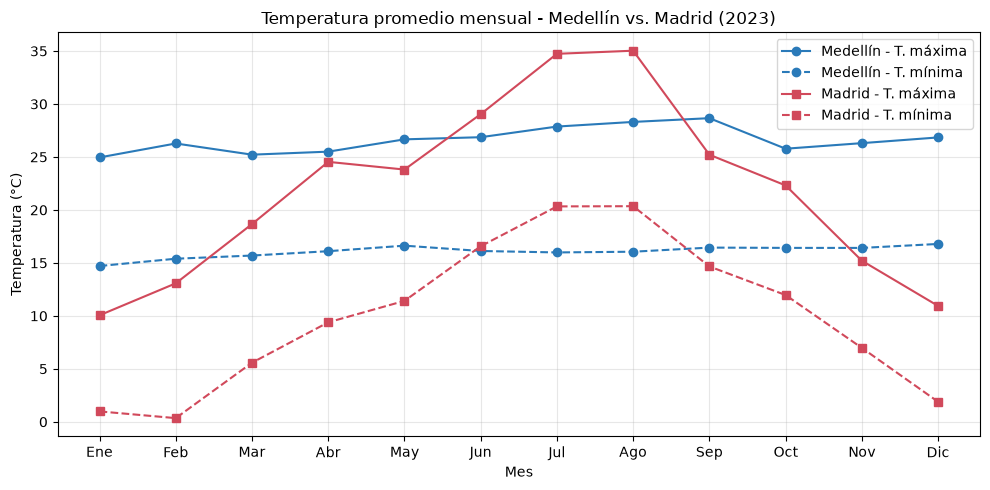

In [9]:
COLOR_MED = "#2a7ab9"
COLOR_MAD = "#d1495b"

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(nombres_meses, tmax_mensual_med, marker="o", color=COLOR_MED, label="Medellín - T. máxima")
ax.plot(nombres_meses, tmin_mensual_med, marker="o", color=COLOR_MED, linestyle="--", label="Medellín - T. mínima")
ax.plot(nombres_meses, tmax_mensual_mad, marker="s", color=COLOR_MAD, label="Madrid - T. máxima")
ax.plot(nombres_meses, tmin_mensual_mad, marker="s", color=COLOR_MAD, linestyle="--", label="Madrid - T. mínima")
ax.set_title("Temperatura promedio mensual - Medellín vs. Madrid (2023)")
ax.set_xlabel("Mes")
ax.set_ylabel("Temperatura (°C)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Patrón observado:** las líneas de Medellín son casi planas: la máxima mensual va de 25.0 °C (enero) a 28.7 °C (septiembre) y la mínima se mantiene entre 14.7 y 16.8 °C.
Madrid dibuja una curva en forma de campana: la máxima sube de 10.1 °C en enero a 35.0 °C en agosto y vuelve a bajar a 10.9 °C en diciembre. Entre junio y agosto Madrid supera a Medellín; el resto del año queda por debajo.

**Qué no permite concluir:** es un solo año (2023), así que no muestra si este comportamiento es típico ni si hay tendencias de largo plazo. Además, los promedios mensuales ocultan los días extremos dentro de cada mes.

### D.2 Barras agrupadas: precipitación acumulada por mes

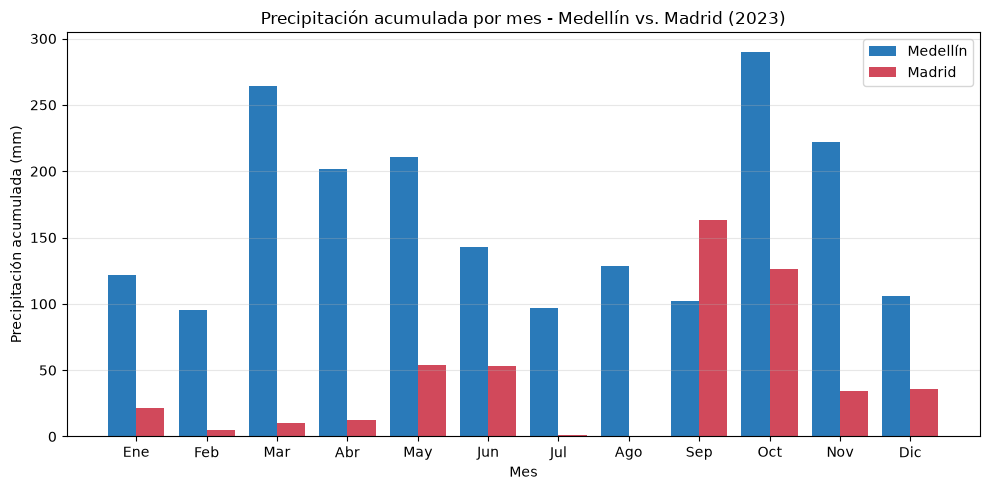

In [10]:
x = np.arange(12)
ancho = 0.4

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - ancho / 2, lluvia_mensual_med, ancho, color=COLOR_MED, label="Medellín")
ax.bar(x + ancho / 2, lluvia_mensual_mad, ancho, color=COLOR_MAD, label="Madrid")
ax.set_xticks(x)
ax.set_xticklabels(nombres_meses)
ax.set_title("Precipitación acumulada por mes - Medellín vs. Madrid (2023)")
ax.set_xlabel("Mes")
ax.set_ylabel("Precipitación acumulada (mm)")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Patrón observado:** Medellín supera a Madrid en lluvia en 11 de los 12 meses; la única excepción es septiembre, cuando Madrid acumuló ≈163 mm frente a ≈102 mm en Medellín. Sus meses más lluviosos fueron octubre (≈290 mm) y marzo (≈264 mm), coherente con un régimen de dos temporadas de lluvia; aun su mes más seco (febrero, ≈96 mm) superó a casi todos los meses de Madrid.
Madrid tuvo un verano casi sin lluvia (julio ≈1 mm y agosto ≈0.4 mm) y concentró buena parte de su precipitación anual en septiembre y octubre (≈163 y ≈126 mm).

**Qué no permite concluir:** el total mensual no dice si la lluvia cayó en muchos días suaves o en pocos aguaceros fuertes. Con un solo año tampoco se puede afirmar que el pico de septiembre en Madrid se repita cada año: puede deberse a eventos puntuales de 2023.

### D.3 Histogramas: amplitud térmica diaria (T. máxima - T. mínima)
Como tercera gráfica se compara la distribución de otra variable derivada: la amplitud térmica diaria calculada con broadcasting en la sección C.4.

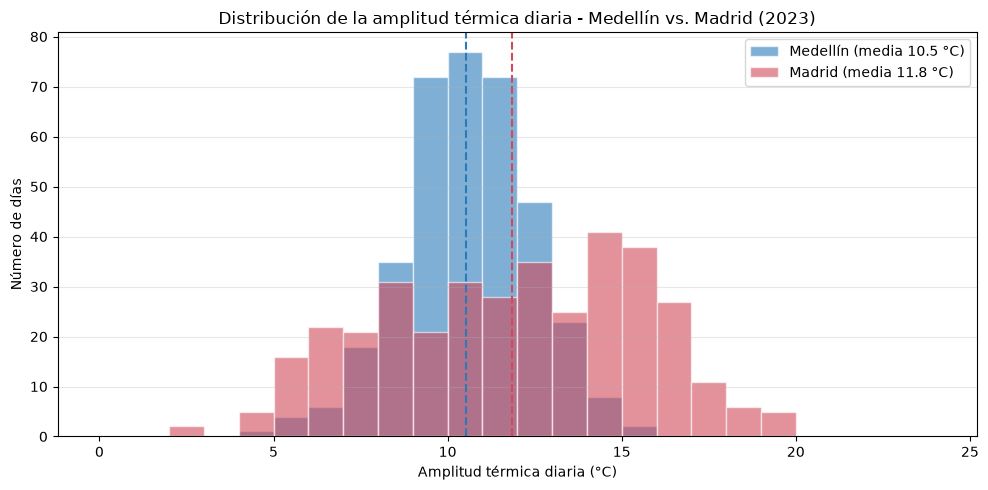

Desviación estándar de la amplitud - Medellín: 1.9 °C | Madrid: 3.7 °C


In [11]:
bins = np.arange(0, 25, 1)   # intervalos de 1 °C, iguales para ambas ciudades

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(amp_med, bins=bins, alpha=0.6, color=COLOR_MED, edgecolor="white", label=f"Medellín (media {amp_med.mean():.1f} °C)")
ax.hist(amp_mad, bins=bins, alpha=0.6, color=COLOR_MAD, edgecolor="white", label=f"Madrid (media {amp_mad.mean():.1f} °C)")
ax.axvline(amp_med.mean(), color=COLOR_MED, linestyle="--")
ax.axvline(amp_mad.mean(), color=COLOR_MAD, linestyle="--")
ax.set_title("Distribución de la amplitud térmica diaria - Medellín vs. Madrid (2023)")
ax.set_xlabel("Amplitud térmica diaria (°C)")
ax.set_ylabel("Número de días")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Desviación estándar de la amplitud - Medellín: {amp_med.std():.1f} °C | Madrid: {amp_mad.std():.1f} °C")

**Patrón observado:** las dos distribuciones se superponen en buena parte y sus promedios están cerca (≈10.5 °C en Medellín y ≈11.8 °C en Madrid). La de Madrid es más ancha: tiene más días con amplitudes muy bajas (días nublados o lluviosos de invierno) y más días con amplitudes por encima de 15 °C (días secos de primavera y verano).

**Qué no permite concluir:** el histograma no indica en qué época del año ocurre cada amplitud ni por qué. Que la amplitud promedio sea parecida no significa que el clima de las dos ciudades sea parecido: las temperaturas de las que parte cada ciudad son muy distintas.

## E. Interpretación de resultados

**Respuesta a la pregunta guía.** Durante 2023, Medellín y Madrid muestran más diferencias que similitudes: Medellín tiene un clima estable y lluvioso todo el año, mientras que Madrid tiene estaciones muy marcadas y es mucho más seca.

### Hallazgo 1 (diferencia): estacionalidad de la temperatura
- La temperatura máxima mensual de Medellín varió solo 3.7 °C a lo largo del año (de 25.0 °C en enero a 28.7 °C en septiembre); la de Madrid varió 24.9 °C (de 10.1 °C en enero a 35.0 °C en agosto).
- La desviación estándar diaria de la temperatura máxima fue ≈1.7 °C en Medellín frente a ≈9.0 °C en Madrid.
- Los extremos absolutos fueron mucho más amplios en Madrid: de -4.4 °C a 40.0 °C, frente a 12.9 °C a 30.4 °C en Medellín.

### Hallazgo 2 (diferencia): cantidad y frecuencia de la lluvia
- Medellín acumuló ≈1 983 mm en 273 días lluviosos (>0.5 mm); Madrid ≈517 mm en 77 días.
- Medellín superó a Madrid en 11 de 12 meses (la excepción fue septiembre: ≈163 mm en Madrid contra ≈102 mm en Medellín); Madrid tuvo un verano prácticamente seco (julio y agosto con menos de 2 mm entre ambos).

### Hallazgo 3 (similitud): días calurosos y amplitud térmica diaria
- Con el mismo umbral de 28 °C, las dos ciudades tuvieron una cantidad parecida de días calurosos: 85 en Medellín y 96 en Madrid. En ambas ciudades se concentran en la segunda mitad del año (75 de 96 en junio-agosto en Madrid; 60 de 85 en julio-septiembre en Medellín), pero en Medellín también aparecen en 10 de los 12 meses, mientras que en Madrid solo aparecen entre abril y octubre.
- La amplitud térmica diaria promedio también es similar: ≈10.5 °C en Medellín y ≈11.8 °C en Madrid.

### Comparación con la predicción
Las predicciones 1, 2 y 3 se cumplieron. Lo que no se anticipó fue que el número de días por encima de 28 °C resultara parecido en las dos ciudades.

### Limitaciones
- **Un solo año:** el periodo común es 2023 completo. Los resultados describen ese año y no permiten hablar de tendencias ni de lo que es "normal" en cada ciudad; un año con fenómenos como El Niño o La Niña podría verse distinto.
- **Datos faltantes:** ninguna de las dos tablas tuvo faltantes ni fechas duplicadas, así que la comparación usa los 365 días completos. Si hubiera faltantes, esos días se habrían eliminado (no rellenado con cero), lo que reduciría la muestra y podría sesgar los totales de lluvia mensuales.
- **Un punto por ciudad:** cada ciudad está representada por una sola coordenada; otras zonas de la misma ciudad pueden registrar valores diferentes.
- **Umbrales elegidos:** los conteos de días lluviosos y calurosos dependen de los umbrales (0.5 mm y 28 °C); con otros umbrales los conteos cambian, como muestra la tabla de la sección C.4.

### Sobre la causalidad
Este análisis describe **asociaciones**: por ejemplo, que Madrid es más cálida en junio-agosto o que Medellín tiene más días lluviosos. Con estos datos no se puede afirmar qué *causa* esas diferencias (latitud, altitud, relieve u otros factores), porque no se midieron ni se controlaron esas variables.